# Experimento de Previsão de Novos Usuários do Trocabook

Este experimento tem como objetivo desenvolver e avaliar uma abordagem para prever a quantidade de novos usuários que poderão se cadastrar no Trocabook com base no histórico de cadastros da plataforma.

A análise utiliza a data de criação dos usuários para construir uma série temporal contendo a quantidade de novos cadastros registrados em cada mês. A partir desse histórico, serão analisados padrões de crescimento e tendências que possam auxiliar na estimativa de cadastros futuros.

A granularidade temporal adotada será mensal, tendo como horizonte principal a previsão de novos usuários para o próximo mês. Também poderão ser produzidas projeções complementares para os próximos 3, 6 e 12 meses, considerando que a incerteza das estimativas tende a aumentar conforme o horizonte de previsão se torna mais distante.

O experimento utilizará inicialmente dados simulados para validar as etapas de preparação, treinamento, avaliação e geração das previsões antes da integração com os dados reais armazenados no Firebase Cloud Firestore.

A avaliação dos modelos respeitará a ordem cronológica dos dados, utilizando períodos anteriores para treinamento e períodos posteriores para teste. Também será utilizada uma estratégia de referência simples (baseline), permitindo verificar se o modelo preditivo apresenta resultados superiores a uma previsão básica.

Os resultados preditivos deste experimento deverão ser interpretados considerando a quantidade e a qualidade do histórico disponível.

## 1. Bibliotecas utilizadas

Para o desenvolvimento deste experimento serão utilizadas bibliotecas voltadas à manipulação de dados, cálculos numéricos, visualização e construção de modelos preditivos.

- **Pandas:** utilizado para organização, transformação e agrupamento dos dados de usuários, incluindo a construção da série temporal mensal de novos cadastros.

- **NumPy:** utilizado como suporte para operações numéricas e manipulação de valores utilizados durante a preparação e avaliação dos dados.

- **Matplotlib:** utilizado para visualizar a evolução histórica dos cadastros e comparar os valores reais com as previsões produzidas pelos modelos.

- **Scikit-learn:** utilizado para construção e avaliação dos modelos preditivos, além do cálculo de métricas que permitirão comparar o desempenho das previsões.

A escolha e utilização específica dos modelos será realizada após a análise inicial da série temporal, evitando definir previamente um algoritmo sem observar as características dos dados.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.linear_model import LinearRegression

## 2. Dados utilizados no experimento

Para validar a metodologia de previsão antes da integração com o Firebase Cloud Firestore, será utilizado inicialmente um conjunto de dados simulados representando usuários cadastrados no Trocabook.

Para este experimento, não são necessárias informações pessoais dos usuários. Será utilizada somente a data de criação de cada registro, representada pelo campo `dataCriacao`.

A partir dessas datas, os usuários serão posteriormente agrupados por mês para construir uma série temporal contendo a quantidade de novos cadastros registrados em cada período.

Os dados simulados serão distribuídos ao longo de diferentes meses, permitindo representar variações e uma possível tendência de crescimento no número de novos usuários.

### 2.1 Simulação dos usuários

Como o experimento ainda não está integrado ao Firebase Cloud Firestore, será criado um conjunto de dados simulados para representar o histórico de cadastros do Trocabook.

Serão simulados 36 meses de registros, abrangendo três anos de histórico. A quantidade de novos usuários apresentará uma tendência geral de crescimento com pequenas variações entre os meses, buscando representar um comportamento mais próximo de dados reais.

Cada quantidade mensal será transformada em registros individuais de usuários contendo um identificador e o campo `dataCriacao`. Dessa forma, a estrutura utilizada no experimento se aproxima dos dados que posteriormente serão obtidos da coleção de usuários do Firestore.

In [2]:
cadastros_por_mes_simulados = [
    18, 20, 19, 22, 21, 24,
    23, 26, 25, 27, 29, 30,
    28, 31, 32, 34, 33, 36,
    35, 38, 37, 40, 42, 43,
    41, 44, 46, 47, 49, 48,
    51, 53, 52, 55, 57, 58
]

In [3]:
meses_simulados = pd.period_range(
    start="2024-01",
    periods=36,
    freq="M"
)

In [4]:
usuarios_simulados = []

contador_usuario = 1

for mes, quantidade in zip(
    meses_simulados,
    cadastros_por_mes_simulados
):
    for _ in range(quantidade):
        usuarios_simulados.append({
            "id": f"U{contador_usuario}",
            "dataCriacao": mes.to_timestamp()
        })

        contador_usuario += 1

In [5]:
usuarios = pd.DataFrame(usuarios_simulados)

### 2.2 Visualização inicial

Antes de iniciar a preparação da série temporal, será realizada uma verificação inicial dos dados simulados.

Essa etapa permite observar a estrutura do DataFrame, os primeiros e últimos registros, os tipos das colunas e o intervalo de datas disponível, além de confirmar a quantidade total de usuários gerados para o experimento.

In [6]:
usuarios.head()

,id,dataCriacao
0,U1,2024-01-01
1,U2,2024-01-01
2,U3,2024-01-01
3,U4,2024-01-01
4,U5,2024-01-01


In [7]:
usuarios.tail()

,id,dataCriacao
1309,U1310,2026-12-01
1310,U1311,2026-12-01
1311,U1312,2026-12-01
1312,U1313,2026-12-01
1313,U1314,2026-12-01


In [8]:
usuarios.info()

<class 'pandas.DataFrame'>
RangeIndex: 1314 entries, 0 to 1313
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   id           1314 non-null   str           
 1   dataCriacao  1314 non-null   datetime64[us]
dtypes: datetime64[us](1), str(1)
memory usage: 20.7 KB


In [9]:
print(f"Total de usuários simulados: {len(usuarios)}")
print(f"Primeira data: {usuarios['dataCriacao'].min()}")
print(f"Última data: {usuarios['dataCriacao'].max()}")

Total de usuários simulados: 1314
Primeira data: 2024-01-01 00:00:00
Última data: 2026-12-01 00:00:00


## 3. Preparação da série temporal

Para realizar previsões sobre a quantidade de novos usuários, os registros individuais de cadastro precisam ser transformados em uma sequência cronológica de observações.

Nesta etapa, as datas de criação dos usuários serão validadas e utilizadas para agrupar os cadastros por mês. Também será verificada a existência de períodos sem registros, garantindo que todos os meses do intervalo analisado estejam representados na série temporal.

O resultado será uma série contendo, para cada mês, a quantidade de novos usuários cadastrados no Trocabook.

### 3.1 Validação das datas

Antes do agrupamento mensal, é necessário garantir que o campo `dataCriacao` esteja representado como uma informação temporal válida.

A conversão para o tipo `datetime` permite utilizar os recursos temporais do Pandas nas etapas seguintes. Também será verificada a existência de datas ausentes ou inválidas, pois registros sem uma data de criação válida não podem ser corretamente associados a um período da série temporal.

In [10]:
usuarios["dataCriacao"] = pd.to_datetime(
    usuarios["dataCriacao"],
    errors="coerce"
)

In [11]:
usuarios["dataCriacao"].dtype

dtype('<M8[us]')

In [12]:
usuarios["dataCriacao"].isna().sum()

np.int64(0)

### 3.2 Agrupamento dos cadastros por mês

Após a validação das datas, os registros individuais serão agrupados de acordo com o mês em que cada usuário foi cadastrado.

Para isso, será criado um período mensal a partir do campo `dataCriacao`. Em seguida, os registros pertencentes ao mesmo período serão agrupados e contabilizados, permitindo identificar quantos novos usuários foram cadastrados em cada mês.

Esse agrupamento transforma os registros individuais em observações mensais que posteriormente serão utilizadas na construção da série temporal.

In [13]:
usuarios["mesCriacao"] = (
    usuarios["dataCriacao"]
    .dt.to_period("M")
)

In [14]:
usuarios.head()

,id,dataCriacao,mesCriacao
0,U1,2024-01-01,2024-01
1,U2,2024-01-01,2024-01
2,U3,2024-01-01,2024-01
3,U4,2024-01-01,2024-01
4,U5,2024-01-01,2024-01


In [15]:
cadastros_mensais = (
    usuarios
    .groupby("mesCriacao")
    .size()
    .reset_index(name="novosUsuarios")
)

In [16]:
cadastros_mensais

,mesCriacao,novosUsuarios
0,2024-01,18
1,2024-02,20
2,2024-03,19
3,2024-04,22
4,2024-05,21
5,2024-06,24
6,2024-07,23
7,2024-08,26
8,2024-09,25
9,2024-10,27


In [17]:
cadastros_mensais.tail()

,mesCriacao,novosUsuarios
31,2026-08,53
32,2026-09,52
33,2026-10,55
34,2026-11,57
35,2026-12,58


### 3.3 Verificação de períodos sem cadastros

Após o agrupamento mensal, é necessário verificar se todos os meses existentes entre o início e o fim do histórico estão representados na série.

A ausência de um mês no DataFrame não significa necessariamente ausência de informação. Caso nenhum usuário tenha sido cadastrado naquele período, o agrupamento simplesmente não produzirá uma linha para esse mês. Para a análise temporal, entretanto, esse período deve permanecer na série com a quantidade de novos usuários igual a zero.

Nesta etapa, será criado o intervalo completo de meses e comparado com os períodos presentes nos dados, permitindo identificar eventuais meses ausentes.

In [18]:
periodos_completos = pd.period_range(
    start=cadastros_mensais["mesCriacao"].min(),
    end=cadastros_mensais["mesCriacao"].max(),
    freq="M"
)

periodos_completos

PeriodIndex(['2024-01', '2024-02', '2024-03', '2024-04', '2024-05', '2024-06',
             '2024-07', '2024-08', '2024-09', '2024-10', '2024-11', '2024-12',
             '2025-01', '2025-02', '2025-03', '2025-04', '2025-05', '2025-06',
             '2025-07', '2025-08', '2025-09', '2025-10', '2025-11', '2025-12',
             '2026-01', '2026-02', '2026-03', '2026-04', '2026-05', '2026-06',
             '2026-07', '2026-08', '2026-09', '2026-10', '2026-11', '2026-12'],
            dtype='period[M]')

In [19]:
periodos_ausentes = periodos_completos.difference(
    cadastros_mensais["mesCriacao"]
)

periodos_ausentes

PeriodIndex([], dtype='period[M]')

### 3.4 Construção da série temporal

Após identificar o intervalo completo de meses, será construída a série temporal definitiva utilizada nas próximas etapas do experimento.

O DataFrame de cadastros mensais será reorganizado utilizando todos os períodos existentes entre o início e o fim do histórico. Caso algum mês não possua registros de novos usuários, esse período será mantido na série com o valor zero.

Essa etapa garante uma sequência temporal contínua, requisito importante para a análise da evolução dos cadastros e para o treinamento dos modelos preditivos.

In [20]:
serie_usuarios = (
    cadastros_mensais
    .set_index("mesCriacao")
    .reindex(periodos_completos, fill_value=0)
    .rename_axis("mesCriacao")
    .reset_index()
)

serie_usuarios

,mesCriacao,novosUsuarios
0,2024-01,18
1,2024-02,20
2,2024-03,19
3,2024-04,22
4,2024-05,21
5,2024-06,24
6,2024-07,23
7,2024-08,26
8,2024-09,25
9,2024-10,27


In [21]:
print(f"Quantidade de períodos: {len(serie_usuarios)}")
print(f"Primeiro período: {serie_usuarios['mesCriacao'].min()}")
print(f"Último período: {serie_usuarios['mesCriacao'].max()}")
print(f"Períodos com zero cadastros: {(serie_usuarios['novosUsuarios'] == 0).sum()}")

Quantidade de períodos: 36
Primeiro período: 2024-01
Último período: 2026-12
Períodos com zero cadastros: 0


## 4. Análise exploratória da evolução dos usuários

Antes da construção de um modelo preditivo, é importante compreender o comportamento histórico da série temporal.

Nesta etapa, será analisada a evolução mensal dos novos cadastros, observando variações entre os períodos, medidas descritivas e o comportamento geral de crescimento ao longo do tempo.

Essa análise auxilia na identificação das características da série e fornece informações para a escolha e posterior avaliação da abordagem de previsão.

### 4.1 Evolução mensal dos novos cadastros

A primeira análise consiste em observar a quantidade de novos usuários registrada em cada mês do histórico.

A representação gráfica da série permite visualizar as oscilações entre os períodos e verificar se existe um comportamento geral de crescimento, estabilidade ou redução dos cadastros ao longo do tempo.

In [22]:
serie_usuarios["dataMes"] = (
    serie_usuarios["mesCriacao"]
    .dt.to_timestamp()
)

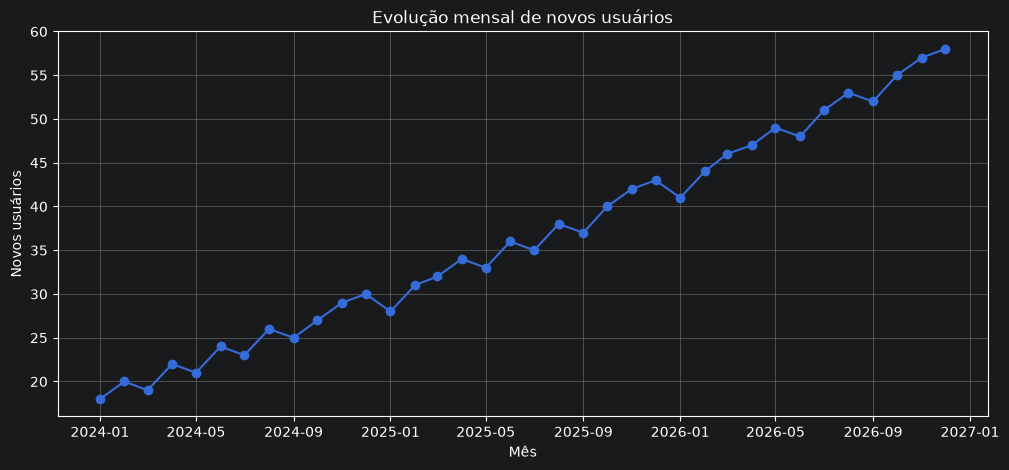

In [23]:
plt.figure(figsize=(12, 5))

plt.plot(
    serie_usuarios["dataMes"],
    serie_usuarios["novosUsuarios"],
    marker="o"
)

plt.title("Evolução mensal de novos usuários")
plt.xlabel("Mês")
plt.ylabel("Novos usuários")
plt.grid(True)
plt.show()

### 4.2 Estatísticas descritivas

Após a visualização da evolução mensal dos cadastros, serão calculadas estatísticas descritivas sobre a quantidade de novos usuários registrados em cada período.

Essas medidas permitem resumir numericamente o comportamento da série, identificando valores como média, mediana, mínimo, máximo e dispersão dos cadastros mensais.

A análise complementa a representação gráfica e fornece uma visão geral da distribuição dos valores observados ao longo do histórico.

In [24]:
serie_usuarios["novosUsuarios"].describe()

count    36.000000
mean     36.500000
std      11.814035
min      18.000000
25%      26.750000
50%      35.500000
75%      46.250000
max      58.000000
Name: novosUsuarios, dtype: float64

In [25]:
media_mensal = serie_usuarios["novosUsuarios"].mean()
mediana_mensal = serie_usuarios["novosUsuarios"].median()
minimo_mensal = serie_usuarios["novosUsuarios"].min()
maximo_mensal = serie_usuarios["novosUsuarios"].max()

print(f"Média mensal: {media_mensal:.2f}")
print(f"Mediana mensal: {mediana_mensal:.2f}")
print(f"Menor quantidade mensal: {minimo_mensal}")
print(f"Maior quantidade mensal: {maximo_mensal}")

Média mensal: 36.50
Mediana mensal: 35.50
Menor quantidade mensal: 18
Maior quantidade mensal: 58


### 4.3 Crescimento observado

Além das estatísticas descritivas, é importante analisar como a quantidade de novos usuários se modifica ao longo do tempo.

Nesta etapa, serão calculadas as variações absoluta e percentual entre meses consecutivos, permitindo identificar períodos de crescimento e redução nos novos cadastros. Também será calculado o crescimento observado entre o primeiro e o último período da série.

Esses indicadores descrevem o comportamento histórico dos dados e não representam, por si só, previsões sobre o crescimento futuro da plataforma.

#### 4.3.1 Variação absoluta mensal

A variação absoluta mensal representa a diferença entre a quantidade de novos usuários de um mês e a quantidade registrada no mês anterior.

Valores positivos indicam aumento nos cadastros, valores negativos indicam redução e o valor zero representa ausência de alteração entre os dois períodos.

In [26]:
serie_usuarios["variacaoAbsoluta"] = (
    serie_usuarios["novosUsuarios"]
    .diff()
)

serie_usuarios[
    ["mesCriacao", "novosUsuarios", "variacaoAbsoluta"]
].head(10)

,mesCriacao,novosUsuarios,variacaoAbsoluta
0,2024-01,18,NaN
1,2024-02,20,2.0
2,2024-03,19,-1.0
3,2024-04,22,3.0
4,2024-05,21,-1.0
5,2024-06,24,3.0
6,2024-07,23,-1.0
7,2024-08,26,3.0
8,2024-09,25,-1.0
9,2024-10,27,2.0


#### 4.3.2 Variação percentual mensal

A variação percentual permite analisar a mudança entre dois meses consecutivos considerando o tamanho do valor registrado no período anterior.

Dessa forma, além de identificar quantos usuários foram adicionados ou reduzidos em relação ao mês anterior, é possível observar a proporção dessa mudança em termos percentuais.

In [27]:
serie_usuarios["variacaoPercentual"] = (
    serie_usuarios["novosUsuarios"]
    .pct_change()
    * 100
)

serie_usuarios[
    [
        "mesCriacao",
        "novosUsuarios",
        "variacaoAbsoluta",
        "variacaoPercentual"
    ]
].head(10)

,mesCriacao,novosUsuarios,variacaoAbsoluta,variacaoPercentual
0,2024-01,18,NaN,NaN
1,2024-02,20,2.0,11.111111
2,2024-03,19,-1.0,-5.000000
3,2024-04,22,3.0,15.789474
4,2024-05,21,-1.0,-4.545455
5,2024-06,24,3.0,14.285714
6,2024-07,23,-1.0,-4.166667
7,2024-08,26,3.0,13.043478
8,2024-09,25,-1.0,-3.846154
9,2024-10,27,2.0,8.000000


#### 4.3.3 Crescimento entre o primeiro e o último período

Para complementar as variações mensais, será comparada a quantidade de novos usuários registrada no primeiro e no último período do histórico.

Essa comparação permite quantificar a diferença absoluta e percentual entre as extremidades da série. O resultado representa o crescimento observado no período analisado e não deve ser interpretado como uma taxa mensal de crescimento ou como uma previsão futura.

In [28]:
primeiro_valor = serie_usuarios["novosUsuarios"].iloc[0]
ultimo_valor = serie_usuarios["novosUsuarios"].iloc[-1]

crescimento_absoluto = ultimo_valor - primeiro_valor

crescimento_percentual = (
    crescimento_absoluto
    / primeiro_valor
    * 100
)

print(f"Primeiro período: {primeiro_valor} novos usuários")
print(f"Último período: {ultimo_valor} novos usuários")
print(f"Crescimento absoluto: {crescimento_absoluto} usuários")
print(f"Crescimento percentual: {crescimento_percentual:.2f}%")

Primeiro período: 18 novos usuários
Último período: 58 novos usuários
Crescimento absoluto: 40 usuários
Crescimento percentual: 222.22%


### 4.4 Tendência histórica

Além das variações observadas entre meses consecutivos, é importante analisar o comportamento geral dos cadastros ao longo do tempo.

Como a quantidade de novos usuários pode apresentar oscilações mensais, será utilizada uma média móvel para suavizar essas variações e facilitar a visualização da tendência histórica da série.

Essa análise permite observar com maior clareza se os cadastros apresentam um comportamento geral de crescimento, estabilidade ou redução ao longo do período analisado.

#### 4.4.1 Média móvel

Para suavizar as oscilações mensais da série, será calculada uma média móvel considerando uma janela de três meses.

Para cada período, a média móvel será calculada utilizando a quantidade de novos usuários do mês atual e dos dois meses anteriores. Dessa forma, pequenas variações entre meses consecutivos possuem menor influência na visualização do comportamento geral da série.

In [29]:
serie_usuarios["mediaMovel3Meses"] = (
    serie_usuarios["novosUsuarios"]
    .rolling(window=3)
    .mean()
)

serie_usuarios[
    ["mesCriacao", "novosUsuarios", "mediaMovel3Meses"]
].head(10)

,mesCriacao,novosUsuarios,mediaMovel3Meses
0,2024-01,18,NaN
1,2024-02,20,NaN
2,2024-03,19,19.000000
3,2024-04,22,20.333333
4,2024-05,21,20.666667
5,2024-06,24,22.333333
6,2024-07,23,22.666667
7,2024-08,26,24.333333
8,2024-09,25,24.666667
9,2024-10,27,26.000000


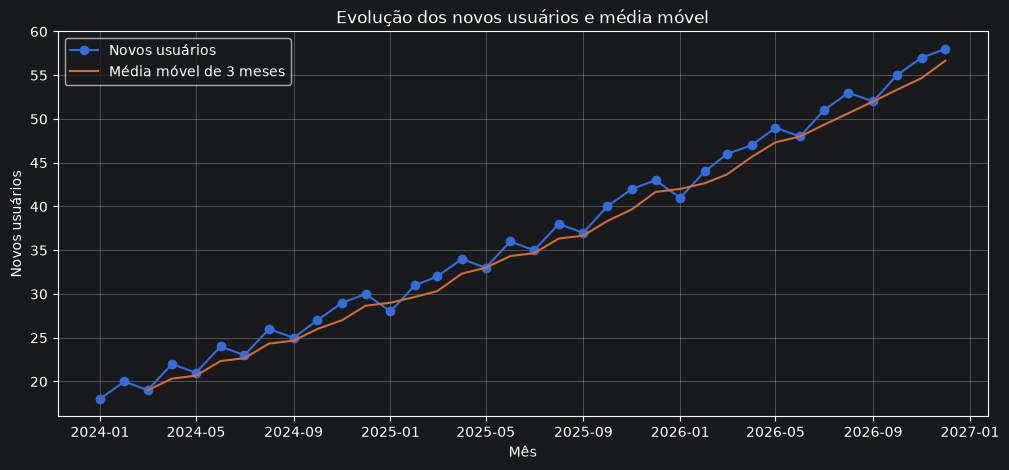

In [30]:
plt.figure(figsize=(12, 5))

plt.plot(
    serie_usuarios["dataMes"],
    serie_usuarios["novosUsuarios"],
    marker="o",
    label="Novos usuários"
)

plt.plot(
    serie_usuarios["dataMes"],
    serie_usuarios["mediaMovel3Meses"],
    label="Média móvel de 3 meses"
)

plt.title("Evolução dos novos usuários e média móvel")
plt.xlabel("Mês")
plt.ylabel("Novos usuários")
plt.legend()
plt.grid(True)
plt.show()

## 5. Preparação para a previsão

Após a análise exploratória da série temporal, os dados serão preparados para a etapa de previsão.

Como os registros possuem uma ordem cronológica, a avaliação deve preservar essa sequência. Dessa forma, os períodos mais antigos serão utilizados para treinamento e os períodos mais recentes serão reservados para teste, evitando que informações futuras sejam utilizadas para prever períodos anteriores.

Também será construída uma estratégia simples de referência (baseline), que servirá como comparação para avaliar posteriormente se o modelo preditivo apresenta desempenho superior a uma previsão básica.

### 5.1 Divisão cronológica entre treino e teste

Para avaliar uma abordagem de previsão temporal, os dados não devem ser divididos aleatoriamente, pois isso poderia misturar períodos futuros com períodos anteriores.

Neste experimento, os primeiros 30 meses serão utilizados como conjunto de treinamento e os últimos 6 meses como conjunto de teste. Dessa forma, a avaliação simula uma situação em que somente o histórico anterior está disponível para estimar períodos futuros.

O conjunto de teste permanecerá separado durante a preparação do modelo e será utilizado posteriormente para comparar as previsões com os valores realmente observados.

In [31]:
quantidade_teste = 6

treino = serie_usuarios.iloc[:-quantidade_teste].copy()
teste = serie_usuarios.iloc[-quantidade_teste:].copy()

In [32]:
print(f"Períodos de treinamento: {len(treino)}")
print(f"Períodos de teste: {len(teste)}")

print(
    f"Treinamento: "
    f"{treino['mesCriacao'].min()} até "
    f"{treino['mesCriacao'].max()}"
)

print(
    f"Teste: "
    f"{teste['mesCriacao'].min()} até "
    f"{teste['mesCriacao'].max()}"
)

Períodos de treinamento: 30
Períodos de teste: 6
Treinamento: 2024-01 até 2026-06
Teste: 2026-07 até 2026-12


### 5.2 Baseline de persistência

Antes da construção do modelo preditivo, será utilizada uma estratégia simples de referência (baseline) para avaliar a dificuldade do problema e estabelecer um desempenho mínimo de comparação.

O baseline adotado será o modelo de persistência, no qual a previsão para um determinado mês corresponde à quantidade de novos usuários observada no mês imediatamente anterior.

Posteriormente, os erros produzidos por essa estratégia serão comparados aos erros do modelo preditivo. Dessa forma, será possível verificar se a utilização de um modelo mais elaborado apresenta melhoria em relação a uma previsão simples.

In [33]:
previsoes_baseline = []

ultimo_valor = treino["novosUsuarios"].iloc[-1]

for valor_real in teste["novosUsuarios"]:
    previsoes_baseline.append(ultimo_valor)
    ultimo_valor = valor_real

teste["previsaoBaseline"] = previsoes_baseline

teste[
    ["mesCriacao", "novosUsuarios", "previsaoBaseline"]
]

,mesCriacao,novosUsuarios,previsaoBaseline
30,2026-07,51,48
31,2026-08,53,51
32,2026-09,52,53
33,2026-10,55,52
34,2026-11,57,55
35,2026-12,58,57


#### 5.2.1 Avaliação do baseline

Após a geração das previsões do baseline, seu desempenho será avaliado por meio de métricas de erro.

Serão utilizadas as métricas MAE (Mean Absolute Error) e RMSE (Root Mean Squared Error). O MAE representa a magnitude média dos erros das previsões, enquanto o RMSE atribui maior peso aos erros de maior magnitude.

Essas métricas serão posteriormente utilizadas também na avaliação do modelo preditivo, permitindo uma comparação direta entre as duas abordagens.

In [34]:
mae_baseline = mean_absolute_error(
    teste["novosUsuarios"],
    teste["previsaoBaseline"]
)

print(f"MAE do baseline: {mae_baseline:.2f}")

MAE do baseline: 2.00


In [35]:
rmse_baseline = np.sqrt(
    mean_squared_error(
        teste["novosUsuarios"],
        teste["previsaoBaseline"]
    )
)

print(f"RMSE do baseline: {rmse_baseline:.2f}")

RMSE do baseline: 2.16


## 6. Modelo preditivo

Após a construção e avaliação do baseline, será desenvolvido um modelo preditivo para estimar a quantidade de novos usuários do Trocabook.

Considerando o comportamento observado na série simulada, será utilizada inicialmente uma Regressão Linear. Essa abordagem permite representar a relação entre a passagem do tempo e a quantidade de novos cadastros, sendo adequada como primeiro modelo para avaliar a tendência presente nos dados.

O desempenho do modelo será avaliado utilizando o mesmo conjunto de teste e as mesmas métricas aplicadas ao baseline, permitindo verificar se a utilização da Regressão Linear apresenta melhoria na capacidade de previsão.

### 6.1 Representação numérica do tempo

Para utilizar a série temporal em um modelo de Regressão Linear, a passagem do tempo será representada por meio de um índice numérico sequencial.

Cada mês receberá um valor crescente, iniciando em zero para o primeiro período da série. Dessa forma, o modelo poderá analisar a relação entre o avanço do tempo e a quantidade de novos usuários cadastrados.

Essa representação mantém a ordem cronológica dos períodos sem utilizar diretamente as datas como variável de entrada do modelo.

In [36]:
serie_usuarios["indiceTempo"] = np.arange(
    len(serie_usuarios)
)

serie_usuarios[
    ["mesCriacao", "indiceTempo", "novosUsuarios"]
].head(10)

,mesCriacao,indiceTempo,novosUsuarios
0,2024-01,0,18
1,2024-02,1,20
2,2024-03,2,19
3,2024-04,3,22
4,2024-05,4,21
5,2024-06,5,24
6,2024-07,6,23
7,2024-08,7,26
8,2024-09,8,25
9,2024-10,9,27


In [37]:
serie_usuarios[
    ["mesCriacao", "indiceTempo", "novosUsuarios"]
].tail()

,mesCriacao,indiceTempo,novosUsuarios
31,2026-08,31,53
32,2026-09,32,52
33,2026-10,33,55
34,2026-11,34,57
35,2026-12,35,58


### 6.2 Preparação dos dados para a Regressão Linear

Para treinar a Regressão Linear, os dados serão separados entre a variável de entrada (`X`) e a variável que será prevista (`y`).

A variável de entrada será o índice temporal, que representa a passagem dos meses ao longo da série. A variável alvo será a quantidade de novos usuários registrados em cada período.

A separação entre treinamento e teste continuará respeitando a divisão cronológica definida anteriormente, utilizando os primeiros 30 meses para treinamento e os últimos 6 meses para avaliação.

In [38]:
X_treino = serie_usuarios[
    ["indiceTempo"]
].iloc[:-quantidade_teste]

X_teste = serie_usuarios[
    ["indiceTempo"]
].iloc[-quantidade_teste:]

y_treino = serie_usuarios[
    "novosUsuarios"
].iloc[:-quantidade_teste]

y_teste = serie_usuarios[
    "novosUsuarios"
].iloc[-quantidade_teste:]

In [39]:
print(f"X treino: {X_treino.shape}")
print(f"y treino: {y_treino.shape}")

print(f"X teste: {X_teste.shape}")
print(f"y teste: {y_teste.shape}")

X treino: (30, 1)
y treino: (30,)
X teste: (6, 1)
y teste: (6,)


### 6.3 Treinamento da Regressão Linear

Após a preparação das variáveis de entrada e da variável alvo, será realizado o treinamento do modelo de Regressão Linear.

O modelo utilizará os 30 meses pertencentes ao conjunto de treinamento para aprender a relação entre a passagem do tempo e a quantidade de novos usuários cadastrados.

A Regressão Linear busca representar essa relação por meio de uma reta, estimando um coeficiente associado à evolução temporal e um intercepto correspondente ao valor inicial estimado pelo modelo.

In [40]:
modelo_regressao = LinearRegression()

modelo_regressao.fit(
    X_treino,
    y_treino
)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[1.06]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['indiceTempo']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,17.58
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [41]:
coeficiente = modelo_regressao.coef_[0]
intercepto = modelo_regressao.intercept_

print(f"Coeficiente: {coeficiente:.4f}")
print(f"Intercepto: {intercepto:.4f}")

Coeficiente: 1.0590
Intercepto: 17.5785


### 6.4 Previsões no conjunto de teste

Após o treinamento da Regressão Linear, o modelo será utilizado para estimar a quantidade de novos usuários nos seis meses reservados para teste.

Esses períodos não foram utilizados durante o treinamento do modelo. Dessa forma, as previsões poderão ser comparadas aos valores realmente observados, permitindo avaliar a capacidade da Regressão Linear de representar a tendência da série em períodos posteriores aos utilizados no treinamento.

In [42]:
previsoes_regressao = modelo_regressao.predict(
    X_teste
)

previsoes_regressao

array([49.34712644, 50.40608083, 51.46503522, 52.52398962, 53.58294401,
       54.64189841])

In [43]:
resultado_regressao = teste[
    ["mesCriacao", "novosUsuarios", "previsaoBaseline"]
].copy()

resultado_regressao["previsaoRegressao"] = previsoes_regressao

resultado_regressao

,mesCriacao,novosUsuarios,previsaoBaseline,previsaoRegressao
30,2026-07,51,48,49.347126
31,2026-08,53,51,50.406081
32,2026-09,52,53,51.465035
33,2026-10,55,52,52.523990
34,2026-11,57,55,53.582944
35,2026-12,58,57,54.641898


### 6.5 Avaliação da Regressão Linear

Após a geração das previsões, o desempenho da Regressão Linear será avaliado utilizando as mesmas métricas aplicadas ao baseline: MAE (Mean Absolute Error) e RMSE (Root Mean Squared Error).

A utilização das mesmas métricas e do mesmo conjunto de teste permite realizar uma comparação direta entre as duas abordagens, verificando se a Regressão Linear apresenta redução dos erros em relação à estratégia simples de persistência.

In [44]:
mae_regressao = mean_absolute_error(
    y_teste,
    previsoes_regressao
)

rmse_regressao = np.sqrt(
    mean_squared_error(
        y_teste,
        previsoes_regressao
    )
)

print(f"MAE da regressão: {mae_regressao:.2f}")
print(f"RMSE da regressão: {rmse_regressao:.2f}")

MAE da regressão: 2.34
RMSE da regressão: 2.54


### 6.6 Comparação com o baseline

Para verificar se a Regressão Linear apresenta melhoria em relação à estratégia simples de persistência, serão comparados os valores de MAE e RMSE obtidos pelas duas abordagens.

Como valores menores representam erros menores, o modelo com os menores resultados nessas métricas apresenta melhor desempenho no conjunto de teste analisado.

Essa comparação é importante para verificar se a utilização de um modelo preditivo mais elaborado acrescenta capacidade de previsão em relação a uma estratégia simples de referência.

In [45]:
comparacao_modelos = pd.DataFrame({
    "modelo": [
        "Baseline de persistência",
        "Regressão Linear"
    ],
    "MAE": [
        mae_baseline,
        mae_regressao
    ],
    "RMSE": [
        rmse_baseline,
        rmse_regressao
    ]
})

comparacao_modelos

,modelo,MAE,RMSE
0,Baseline de persistência,2.000000,2.160247
1,Regressão Linear,2.338821,2.543958


In [46]:
diferenca_mae_percentual = (
    (mae_regressao - mae_baseline)
    / mae_baseline
    * 100
)

print(
    f"A Regressão Linear apresentou um MAE "
    f"{diferenca_mae_percentual:.2f}% maior que o baseline."
)

A Regressão Linear apresentou um MAE 16.94% maior que o baseline.


#### 6.6.1 Interpretação dos resultados

A comparação das métricas demonstrou que o baseline de persistência apresentou melhor desempenho que a Regressão Linear no conjunto de teste analisado.

O baseline obteve MAE de aproximadamente 2,00 e RMSE de 2,16, enquanto a Regressão Linear apresentou MAE de aproximadamente 2,34 e RMSE de 2,54. Considerando o MAE, o erro da Regressão Linear foi aproximadamente 16,94% maior que o erro obtido pelo baseline.

Esse resultado indica que, para os dados simulados e para a estratégia de previsão de um mês à frente utilizada neste experimento, a Regressão Linear não apresentou melhoria em relação à estratégia simples de persistência.

Embora a série apresente uma tendência geral de crescimento, o baseline consegue incorporar imediatamente o valor observado no mês anterior, enquanto a Regressão Linear representa uma tendência média calculada a partir do conjunto de treinamento.

Dessa forma, os resultados reforçam a importância da utilização de uma estratégia de referência para avaliar se a adoção de um modelo preditivo mais elaborado realmente acrescenta capacidade de previsão.

#### 6.6.2 Comparação visual das previsões

Além da comparação por meio das métricas de erro, os valores reais e as previsões produzidas pelo baseline de persistência e pela Regressão Linear serão representados graficamente.

A visualização permite observar o comportamento das duas abordagens ao longo do conjunto de teste e auxilia na interpretação das diferenças identificadas pelas métricas MAE e RMSE.

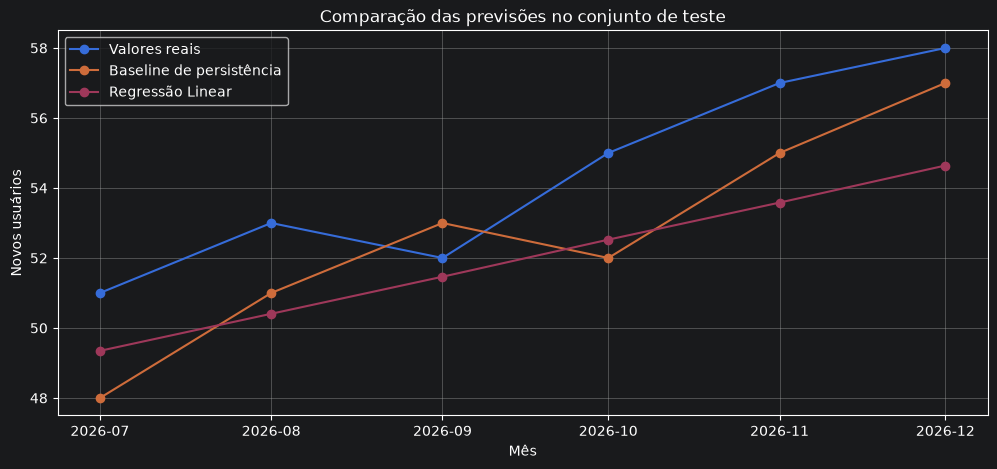

In [47]:
plt.figure(figsize=(12, 5))

plt.plot(
    resultado_regressao["mesCriacao"].dt.to_timestamp(),
    resultado_regressao["novosUsuarios"],
    marker="o",
    label="Valores reais"
)

plt.plot(
    resultado_regressao["mesCriacao"].dt.to_timestamp(),
    resultado_regressao["previsaoBaseline"],
    marker="o",
    label="Baseline de persistência"
)

plt.plot(
    resultado_regressao["mesCriacao"].dt.to_timestamp(),
    resultado_regressao["previsaoRegressao"],
    marker="o",
    label="Regressão Linear"
)

plt.title("Comparação das previsões no conjunto de teste")
plt.xlabel("Mês")
plt.ylabel("Novos usuários")
plt.legend()
plt.grid(True)
plt.show()

### 6.7 Considerações sobre a escolha do modelo

Os resultados obtidos neste experimento não permitem considerar a Regressão Linear como o modelo definitivo para a previsão de novos usuários do Trocabook.

No conjunto de teste utilizado, o baseline de persistência apresentou menores valores de MAE e RMSE para previsões de um mês à frente, demonstrando desempenho superior à Regressão Linear nesse cenário.

A Regressão Linear foi utilizada como uma primeira abordagem preditiva devido à tendência de crescimento observada nos dados simulados e à facilidade de interpretação de seus resultados. Entretanto, seu uso neste experimento não implica que ela seja o modelo ideal ou definitivo para os dados reais da plataforma.

A escolha de um modelo definitivo deverá ser reavaliada após a integração com os dados reais do Trocabook, considerando a quantidade de histórico disponível, o comportamento da série temporal, a possível presença de sazonalidade e o desempenho de diferentes abordagens de previsão.

Dessa forma, a Regressão Linear será mantida nas próximas etapas como uma abordagem experimental para projeção da tendência observada, e não como o modelo final selecionado para o serviço de Analytics.

#### Considerações sobre os hiperparâmetros

A Regressão Linear utilizada neste experimento possui poucos hiperparâmetros relacionados diretamente ao processo de aprendizagem. Por esse motivo, não foi realizada uma etapa específica de otimização de hiperparâmetros.

Foi mantida a configuração padrão com intercepto, permitindo que o modelo estime livremente a relação entre o tempo e a quantidade de novos usuários.

A avaliação experimental concentrou-se na comparação do desempenho da Regressão Linear com o baseline de persistência. Com a utilização futura dos dados reais do Trocabook, outros modelos e configurações poderão ser avaliados caso as características da série temporal justifiquem maior complexidade.

## 7. Projeções futuras

Após a avaliação realizada no conjunto de teste, serão produzidas projeções experimentais para períodos futuros.

Embora a Regressão Linear não tenha superado o baseline de persistência na previsão de um mês à frente, ela será utilizada nesta etapa para demonstrar a projeção da tendência temporal aprendida a partir do histórico.

Essa utilização não representa a escolha definitiva da Regressão Linear como modelo de previsão do Trocabook. O objetivo é avaliar seu comportamento em diferentes horizontes e demonstrar como projeções futuras poderão ser produzidas pelo serviço de Analytics.

As projeções de maior horizonte devem ser interpretadas com cautela, pois a incerteza tende a aumentar conforme a previsão se distancia dos dados observados. A escolha definitiva do modelo deverá ser reavaliada com dados reais e histórico suficiente da plataforma.

### 7.1 Treinamento com todo o histórico

Para a geração das projeções experimentais, a Regressão Linear será novamente treinada utilizando todo o histórico disponível.

Durante a etapa de avaliação, os últimos seis meses foram mantidos separados para permitir a comparação das previsões com valores conhecidos. Após essa avaliação, esses períodos podem ser incorporados novamente ao conjunto de treinamento.

Dessa forma, a projeção da tendência futura utilizará todos os 36 meses simulados disponíveis no experimento.

In [48]:
X_completo = serie_usuarios[
    ["indiceTempo"]
]

y_completo = serie_usuarios[
    "novosUsuarios"
]

In [49]:
print(f"X completo: {X_completo.shape}")
print(f"y completo: {y_completo.shape}")

X completo: (36, 1)
y completo: (36,)


In [50]:
modelo_regressao_final = LinearRegression()

modelo_regressao_final.fit(
    X_completo,
    y_completo
)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[1.11]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['indiceTempo']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,16.99
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


### 7.2 Preparação dos períodos futuros

Para gerar projeções futuras, serão criados os índices temporais correspondentes aos 12 meses posteriores ao último período disponível no histórico.

Como a série observada termina no índice 35, correspondente a dezembro de 2026, os períodos futuros serão representados pelos índices de 36 a 47.

Também serão criados os respectivos períodos mensais, permitindo associar cada previsão produzida pelo modelo ao mês correspondente.

In [51]:
ultimo_indice = serie_usuarios["indiceTempo"].max()

indices_futuros = np.arange(
    ultimo_indice + 1,
    ultimo_indice + 13
)

indices_futuros

array([36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47])

In [52]:
ultimo_mes = serie_usuarios["mesCriacao"].max()

meses_futuros = pd.period_range(
    start=ultimo_mes + 1,
    periods=12,
    freq="M"
)

meses_futuros

PeriodIndex(['2027-01', '2027-02', '2027-03', '2027-04', '2027-05', '2027-06',
             '2027-07', '2027-08', '2027-09', '2027-10', '2027-11', '2027-12'],
            dtype='period[M]')

### 7.3 Geração das projeções futuras

Após a definição dos períodos futuros, os respectivos índices temporais serão utilizados como entrada para a Regressão Linear treinada com todo o histórico disponível.

O modelo produzirá uma estimativa da quantidade de novos usuários para cada um dos próximos 12 meses. Essas estimativas representam uma projeção da tendência aprendida a partir dos dados simulados e não devem ser interpretadas como valores garantidos.

As projeções serão associadas aos respectivos meses para facilitar sua análise e posterior utilização pelo serviço de Analytics.

In [53]:
X_futuro = pd.DataFrame({
    "indiceTempo": indices_futuros
})

X_futuro

,indiceTempo
0,36
1,37
2,38
3,39
4,40
5,41
6,42
7,43
8,44
9,45


In [54]:
X_futuro.shape

(12, 1)

In [55]:
previsoes_futuras = modelo_regressao_final.predict(
    X_futuro
)

previsoes_futuras

array([57.12380952, 58.23861004, 59.35341055, 60.46821107, 61.58301158,
       62.6978121 , 63.81261261, 64.92741313, 66.04221364, 67.15701416,
       68.27181467, 69.38661519])

In [56]:
projecoes_futuras = pd.DataFrame({
    "mes": meses_futuros,
    "indiceTempo": indices_futuros,
    "novosUsuariosEstimados": previsoes_futuras
})

projecoes_futuras

,mes,indiceTempo,novosUsuariosEstimados
0,2027-01,36,57.123810
1,2027-02,37,58.238610
2,2027-03,38,59.353411
3,2027-04,39,60.468211
4,2027-05,40,61.583012
5,2027-06,41,62.697812
6,2027-07,42,63.812613
7,2027-08,43,64.927413
8,2027-09,44,66.042214
9,2027-10,45,67.157014


In [57]:
projecoes_futuras.tail()

,mes,indiceTempo,novosUsuariosEstimados
7,2027-08,43,64.927413
8,2027-09,44,66.042214
9,2027-10,45,67.157014
10,2027-11,46,68.271815
11,2027-12,47,69.386615


### 7.4 Visualização das projeções futuras

Para facilitar a interpretação das projeções produzidas pela Regressão Linear, será apresentada uma comparação visual entre o histórico de novos usuários e os valores estimados para os próximos 12 meses.

A separação entre os valores observados e projetados permite identificar onde termina o histórico disponível e onde começam as estimativas produzidas pelo modelo.

Como as projeções representam a continuação da tendência aprendida pela Regressão Linear, os valores futuros devem ser interpretados como estimativas experimentais e não como quantidades garantidas de novos cadastros.

In [58]:
datas_futuras = (
    projecoes_futuras["mes"]
    .dt.to_timestamp()
)

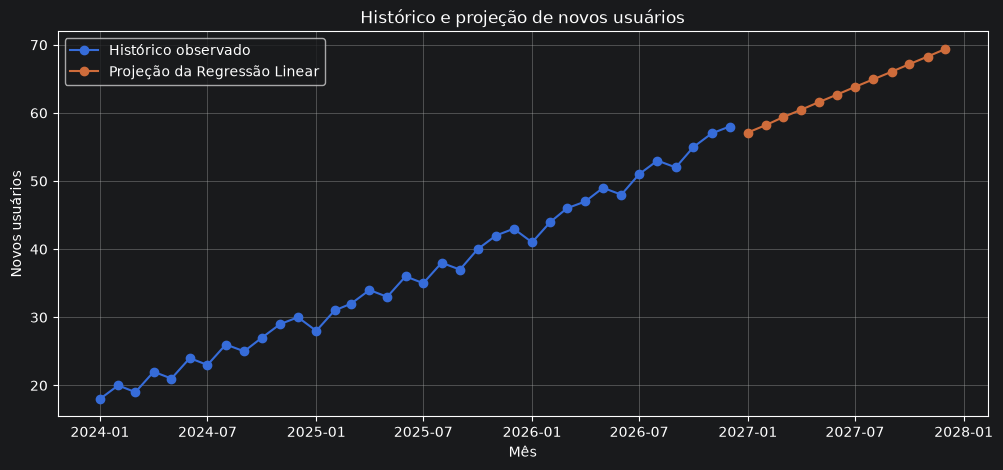

In [59]:
plt.figure(figsize=(12, 5))

plt.plot(
    serie_usuarios["dataMes"],
    serie_usuarios["novosUsuarios"],
    marker="o",
    label="Histórico observado"
)

plt.plot(
    datas_futuras,
    projecoes_futuras["novosUsuariosEstimados"],
    marker="o",
    label="Projeção da Regressão Linear"
)

plt.title("Histórico e projeção de novos usuários")
plt.xlabel("Mês")
plt.ylabel("Novos usuários")
plt.legend()
plt.grid(True)
plt.show()

### 7.5 Projeções por horizonte

Além das estimativas mensais, serão calculadas projeções agregadas para diferentes horizontes temporais.

O horizonte de 1 mês representa a quantidade estimada de novos usuários para o próximo mês. Já os horizontes de 3, 6 e 12 meses representam a soma das estimativas mensais dentro de cada período, indicando a quantidade acumulada de novos cadastros esperada ao longo desses intervalos.

Esses resultados são derivados das projeções experimentais produzidas pela Regressão Linear e, portanto, não representam valores garantidos. A interpretação deve considerar que a incerteza tende a aumentar conforme o horizonte de previsão se torna mais distante.

In [60]:
projecao_1_mes = (
    projecoes_futuras["novosUsuariosEstimados"]
    .iloc[0]
)

projecao_1_mes

np.float64(57.12380952380951)

In [62]:
projecao_3_meses = (
    projecoes_futuras["novosUsuariosEstimados"]
    .iloc[:3]
    .sum()
)

projecao_3_meses

np.float64(174.7158301158301)

In [63]:
projecao_6_meses = (
    projecoes_futuras["novosUsuariosEstimados"]
    .iloc[:6]
    .sum()
)

projecao_6_meses

np.float64(359.4648648648648)

In [64]:
projecao_12_meses = (
    projecoes_futuras["novosUsuariosEstimados"]
    .iloc[:12]
    .sum()
)

projecao_12_meses

np.float64(759.0625482625481)

In [65]:
resumo_horizontes = pd.DataFrame({
    "horizonte": [
        "1 mês",
        "3 meses",
        "6 meses",
        "12 meses"
    ],
    "novosUsuariosEstimados": [
        projecao_1_mes,
        projecao_3_meses,
        projecao_6_meses,
        projecao_12_meses
    ]
})

resumo_horizontes

,horizonte,novosUsuariosEstimados
0,1 mês,57.123810
1,3 meses,174.715830
2,6 meses,359.464865
3,12 meses,759.062548


### 7.6 Preparação da resposta para o serviço de Analytics

Durante as etapas de análise e avaliação, as projeções foram mantidas com seus valores decimais originais para preservar o resultado produzido pelo modelo.

Entretanto, como a quantidade de usuários representa uma contagem discreta, a apresentação desses resultados pelo serviço de Analytics pode utilizar valores inteiros arredondados.

Além do valor numérico, poderão ser produzidos textos interpretativos para facilitar a apresentação das projeções no dashboard administrativo. Esses textos utilizarão termos como "aproximadamente", deixando explícito que os resultados representam estimativas e não quantidades garantidas de novos cadastros.

Essa transformação corresponde à preparação da resposta para consumo da aplicação e não modifica os valores originais utilizados durante a análise do modelo.

In [66]:
resumo_horizontes["valorArredondado"] = (
    resumo_horizontes["novosUsuariosEstimados"]
    .round()
    .astype(int)
)

resumo_horizontes

,horizonte,novosUsuariosEstimados,valorArredondado
0,1 mês,57.123810,57
1,3 meses,174.715830,175
2,6 meses,359.464865,359
3,12 meses,759.062548,759


In [69]:
textos_horizontes = [
    f"Aproximadamente {resumo_horizontes['valorArredondado'].iloc[0]} novos usuários no próximo mês",
    f"Aproximadamente {resumo_horizontes['valorArredondado'].iloc[1]} novos usuários nos próximos 3 meses",
    f"Aproximadamente {resumo_horizontes['valorArredondado'].iloc[2]} novos usuários nos próximos 6 meses",
    f"Aproximadamente {resumo_horizontes['valorArredondado'].iloc[3]} novos usuários nos próximos 12 meses"
]

resumo_horizontes["texto"] = textos_horizontes

resumo_horizontes

,horizonte,novosUsuariosEstimados,valorArredondado,texto
0,1 mês,57.123810,57,Aproximadamente 57 novos usuários no próximo mês
1,3 meses,174.715830,175,Aproximadamente 175 novos usuários nos próximo...
2,6 meses,359.464865,359,Aproximadamente 359 novos usuários nos próximo...
3,12 meses,759.062548,759,Aproximadamente 759 novos usuários nos próximo...


### 7.7 Considerações sobre as projeções

As projeções futuras demonstram como o histórico de cadastros poderá ser transformado em informações preditivas para o dashboard administrativo do Trocabook.

Para facilitar a interpretação, os valores destinados à apresentação foram arredondados e acompanhados do termo "aproximadamente", reforçando seu caráter estimativo. Os valores decimais originais foram preservados durante as etapas analíticas.

A Regressão Linear utilizada nesta etapa representa uma abordagem experimental para projeção da tendência observada e não o modelo definitivo do serviço de Analytics. Sua utilização permitiu validar o fluxo completo de preparação dos dados, treinamento, avaliação e geração de projeções futuras.

Além disso, os resultados de maior horizonte devem ser interpretados com maior cautela. Embora o experimento reconheça que a incerteza tende a aumentar em projeções mais distantes, intervalos de previsão ainda não foram calculados nesta etapa.

A definição do modelo utilizado em produção deverá ser reavaliada após a integração com os dados reais do Trocabook e a disponibilidade de histórico suficiente para comparar diferentes abordagens de previsão.

## 8. Conclusão

Este experimento permitiu validar uma abordagem inicial para análise e previsão da quantidade de novos usuários do Trocabook a partir do histórico de cadastros da plataforma.

Inicialmente, as datas de criação dos usuários foram transformadas em uma série temporal mensal, permitindo representar a quantidade de novos cadastros em cada período. A análise exploratória dos dados simulados demonstrou uma tendência geral de crescimento ao longo dos 36 meses analisados, acompanhada de pequenas variações entre os períodos.

Para avaliar a capacidade de previsão, os dados foram separados cronologicamente em conjuntos de treinamento e teste. Como estratégia de referência, foi utilizado um baseline de persistência, no qual a quantidade observada no mês anterior é utilizada como previsão para o mês seguinte.

Em seguida, foi avaliada uma Regressão Linear utilizando o tempo como variável explicativa. No conjunto de teste, o baseline apresentou MAE de aproximadamente 2,00 e RMSE de 2,16, enquanto a Regressão Linear apresentou MAE de aproximadamente 2,34 e RMSE de 2,54. Dessa forma, a Regressão Linear não apresentou melhoria em relação ao baseline para a estratégia de previsão de um mês à frente utilizada neste experimento.

Apesar desse resultado, a Regressão Linear foi mantida como abordagem experimental para demonstrar a geração de projeções de tendência para períodos ainda não observados. Após o treinamento com todo o histórico disponível, foram produzidas estimativas mensais para os 12 meses seguintes e projeções acumuladas para horizontes de 1, 3, 6 e 12 meses.

Os valores destinados à apresentação foram arredondados e acompanhados do termo "aproximadamente", reforçando que representam estimativas e não quantidades garantidas de novos usuários. Os valores decimais originais foram preservados durante as etapas analíticas.

Os resultados obtidos não estabelecem a Regressão Linear como modelo definitivo para o serviço de Analytics do Trocabook. A escolha do modelo utilizado em produção deverá ser reavaliada após a integração com os dados reais armazenados no Firebase Cloud Firestore, considerando a quantidade de histórico disponível, o comportamento da série temporal, possíveis padrões sazonais e a comparação entre diferentes abordagens de previsão.

Também deve ser considerada a incerteza associada às projeções, especialmente em horizontes mais longos. Neste experimento, essa limitação foi reconhecida qualitativamente, mas não foram calculados intervalos de previsão.

Dessa forma, o experimento valida o fluxo necessário para transformar o histórico de cadastros do Trocabook em informações preditivas, abrangendo preparação dos dados, análise exploratória, definição de baseline, treinamento, avaliação, geração de projeções e preparação dos resultados para posterior consumo pelo dashboard administrativo.